In [1]:
import torch

In [2]:
import torchvision
import numpy as np
import scipy
import matplotlib.pyplot as plt
import sklearn
import h5py
import uproot
import os

In [3]:
file_path = "miniSPINE_DATA/practice_train_2k.root"
h5_path = "miniSPINE_DATA/minispine_train.h5"
n_events = 2000
step_size = 100

os.makedirs("miniSPINE_DATA", exist_ok=True)

file = uproot.open(file_path)
data_tree = file["image2d_data_tree"]
seg_tree = file["image2d_segment_tree"]

rows = int(data_tree["_image_v._meta._row_count"].array(library="np")[0][0])
cols = int(data_tree["_image_v._meta._col_count"].array(library="np")[0][0])

print(f"Estrazione e scrittura diretta di {n_events} eventi in {h5_path}...")

# Inizializza il file HDF5 con dataset ridimensionabili lungo la prima dimensione
with h5py.File(h5_path, 'w') as hf:
    img_ds = hf.create_dataset('images', shape=(0, rows, cols), maxshape=(None, rows, cols), 
                               dtype=np.float32, compression="gzip", chunks=(16, rows, cols))
    mask_ds = hf.create_dataset('masks', shape=(0, rows, cols), maxshape=(None, rows, cols), 
                                dtype=np.int64, compression="gzip", chunks=(16, rows, cols))

    total_valid = 0

    for start in range(0, n_events, step_size):
        stop = min(start + step_size, n_events)

        data_chunk = data_tree["_image_v._img"].array(library="np", entry_start=start, entry_stop=stop)
        seg_chunk = seg_tree["_image_v._img"].array(library="np", entry_start=start, entry_stop=stop)

        batch_imgs = []
        batch_masks = []

        for i in range(len(seg_chunk)):
            mask = np.array(seg_chunk[i][0]).reshape(rows, cols)
            if np.max(mask) > 0:
                img = np.array(data_chunk[i][0]).reshape(rows, cols)
                batch_imgs.append(img)
                batch_masks.append(mask)

        # Scrive immediatamente su disco il blocco corrente e libera subito la RAM
        if len(batch_imgs) > 0:
            batch_imgs = np.array(batch_imgs, dtype=np.float32)
            batch_masks = np.array(batch_masks, dtype=np.int64)

            n_new = len(batch_imgs)
            img_ds.resize((total_valid + n_new, rows, cols))
            mask_ds.resize((total_valid + n_new, rows, cols))

            img_ds[total_valid : total_valid + n_new] = batch_imgs
            mask_ds[total_valid : total_valid + n_new] = batch_masks

            total_valid += n_new
            del batch_imgs, batch_masks

        print(f"Eventi processati: [{start} - {stop}] | Eventi salvati su disco: {total_valid}")

print(f"Completato! Salvati {total_valid} eventi validi in {h5_path}.")

Estrazione e scrittura diretta di 2000 eventi in miniSPINE_DATA/minispine_train.h5...
Eventi processati: [0 - 100] | Eventi salvati su disco: 100
Eventi processati: [100 - 200] | Eventi salvati su disco: 200
Eventi processati: [200 - 300] | Eventi salvati su disco: 300
Eventi processati: [300 - 400] | Eventi salvati su disco: 400
Eventi processati: [400 - 500] | Eventi salvati su disco: 500
Eventi processati: [500 - 600] | Eventi salvati su disco: 600
Eventi processati: [600 - 700] | Eventi salvati su disco: 700
Eventi processati: [700 - 800] | Eventi salvati su disco: 800
Eventi processati: [800 - 900] | Eventi salvati su disco: 900
Eventi processati: [900 - 1000] | Eventi salvati su disco: 1000
Eventi processati: [1000 - 1100] | Eventi salvati su disco: 1100
Eventi processati: [1100 - 1200] | Eventi salvati su disco: 1200
Eventi processati: [1200 - 1300] | Eventi salvati su disco: 1300
Eventi processati: [1300 - 1400] | Eventi salvati su disco: 1400
Eventi processati: [1400 - 1500] |

In [4]:
from torch.utils.data import Dataset, DataLoader

class MiniSPINEDataset(Dataset):
    def __init__(self, h5_path):
        self.h5_path = h5_path
        # Legge solo il numero di eventi senza caricare le matrici in RAM
        with h5py.File(h5_path, 'r') as hf:
            self.length = len(hf['images'])
        self.hf = None

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        # Apre il file in modalità lazy: viene letto solo il singolo evento 'idx'
        if self.hf is None:
            self.hf = h5py.File(self.h5_path, 'r')

        img = self.hf['images'][idx]
        mask = self.hf['masks'][idx]

        # Canale singolo (1, 256, 256)
        img = np.expand_dims(img, axis=0)

        # Conversione diretta in tensori PyTorch
        img_tensor = torch.from_numpy(img).float()
        mask_tensor = torch.from_numpy(mask).long()

        return img_tensor, mask_tensor

In [5]:
import torch.nn as nn

class DoubleConv(nn.Module):
    """(Conv2D -> BatchNorm -> ReLU) * 2"""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class MiniUNet(nn.Module):
    def __init__(self, n_channels=1, n_classes=3):
        super(MiniUNet, self).__init__()
        self.n_channels = n_channels
        self.n_classes = n_classes

        # Encoder
        self.inc = DoubleConv(n_channels, 16)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(16, 32))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))

        # Decoder
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(64, 32)

        self.up3 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv(32, 16)

        self.outc = nn.Conv2d(16, n_classes, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        x = self.up1(x4)
        x = torch.cat([x3, x], dim=1)
        x = self.conv_up1(x)

        x = self.up2(x)
        x = torch.cat([x2, x], dim=1)
        x = self.conv_up2(x)

        x = self.up3(x)
        x = torch.cat([x1, x], dim=1)
        x = self.conv_up3(x)

        logits = self.outc(x)
        return logits

# -----------------------------------------
# Test della Rete (Sanity Check Leggero)
# -----------------------------------------
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = MiniUNet(n_channels=1, n_classes=3).to(device)
    model.eval()

    # Batch size = 1 e disabilitazione gradienti per azzerare il carico di memoria
    dummy_input = torch.randn(1, 1, 256, 256).to(device)

    with torch.no_grad():
        output = model(dummy_input)

    print(f"Dispositivo attivo: {device}")
    print(f"Shape dell'input: {dummy_input.shape}")
    print(f"Shape dell'output: {output.shape} -> (Batch, Classi, H, W)")

Dispositivo attivo: cuda
Shape dell'input: torch.Size([1, 1, 256, 256])
Shape dell'output: torch.Size([1, 3, 256, 256]) -> (Batch, Classi, H, W)


In [6]:
import torch.optim as optim

# 1. Setup del dispositivo di calcolo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Addestramento avviato su: {device}")

# 2. Inizializzazione Rete, Loss e Ottimizzatore
# (Assicurati di aver eseguito le classi MiniUNet e MiniSPINEDataset aggiornate)
model = MiniUNet(n_channels=1, n_classes=3).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 3. Setup del DataLoader con Lazy Loading da HDF5
h5_path = "miniSPINE_DATA/minispine_train.h5"
dataset = MiniSPINEDataset(h5_path)

# Batch size calibrato: 16 su GPU dedicata, 8 se eseguito su CPU per non saturare la RAM
batch_size = 16 if torch.cuda.is_available() else 8

# num_workers=0 è essenziale per evitare accessi concorrenti al file HDF5 e crash del socket WSL
dataloader = DataLoader(
    dataset, 
    batch_size=batch_size, 
    shuffle=True, 
    num_workers=0, 
    pin_memory=(device.type == "cuda")
)

# 4. Ciclo di Addestramento (Training Loop)
num_epochs = 10
print(f"Inizio training su {len(dataset)} eventi per {num_epochs} epoche (batch size: {batch_size})...")

for epoch in range(num_epochs):
    model.train()  # Attiva BatchNorm
    running_loss = 0.0

    for batch_idx, (images, masks) in enumerate(dataloader):
        # Trasferimento dati sulla memoria del dispositivo
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        # 4a. Azzera i gradienti accumulati
        optimizer.zero_grad()

        # 4b. Forward Pass
        outputs = model(images)

        # 4c. Calcolo della Cross-Entropy Loss
        loss = criterion(outputs, masks)

        # 4d. Backward Pass (calcolo gradienti)
        loss.backward()

        # 4e. Aggiornamento dei pesi sinaptici
        optimizer.step()

        running_loss += loss.item()

    # Calcolo metrica media di fine epoca
    epoch_loss = running_loss / len(dataloader)
    print(f"Epoca [{epoch+1:02d}/{num_epochs:02d}] - Loss Media: {epoch_loss:.4f}")

# 5. Salvataggio definitivo dei pesi del modello addestrato
weights_path = "miniSPINE_unet_weights.pth"
torch.save(model.state_dict(), weights_path)
print(f"\nAddestramento completato con successo!")
print(f"Pesi salvati correttamente in: {weights_path}")

Addestramento avviato su: cuda
Inizio training su 2000 eventi per 10 epoche (batch size: 16)...
Epoca [01/10] - Loss Media: 0.4341
Epoca [02/10] - Loss Media: 0.0967
Epoca [03/10] - Loss Media: 0.0348
Epoca [04/10] - Loss Media: 0.0177
Epoca [05/10] - Loss Media: 0.0108
Epoca [06/10] - Loss Media: 0.0076
Epoca [07/10] - Loss Media: 0.0055
Epoca [08/10] - Loss Media: 0.0044
Epoca [09/10] - Loss Media: 0.0036
Epoca [10/10] - Loss Media: 0.0030

Addestramento completato con successo!
Pesi salvati correttamente in: miniSPINE_unet_weights.pth


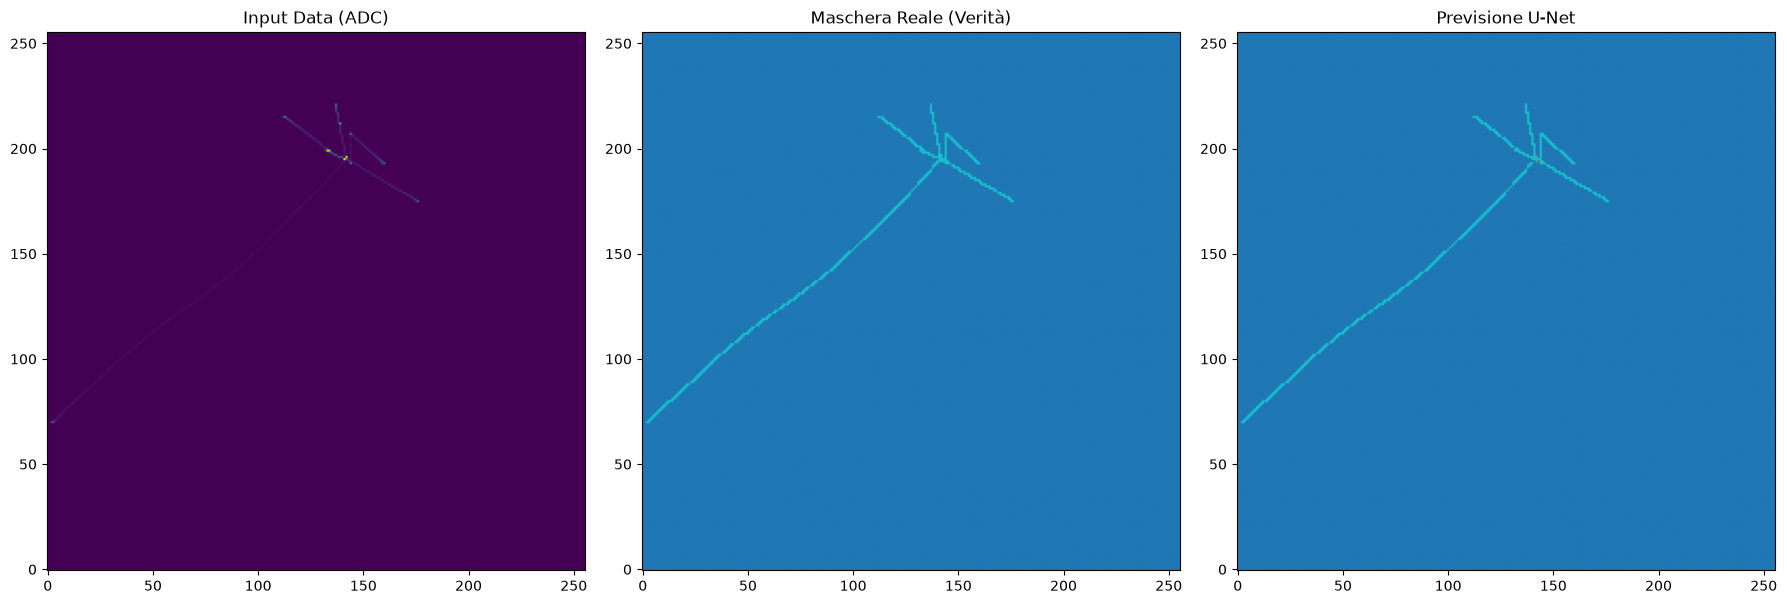

In [7]:
model.eval()

test_images, test_masks = next(iter(dataloader))
test_images = test_images.to(device)
test_masks = test_masks.to(device)

with torch.no_grad():
    predictions = model(test_images)
    pred_labels = torch.argmax(predictions, dim=1)

img_plot = test_images[0, 0].cpu().numpy()
mask_plot = test_masks[0].cpu().numpy()
pred_plot = pred_labels[0].cpu().numpy()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

ax1.imshow(img_plot, cmap='viridis', origin='lower')
ax1.set_title("Input Data (ADC)")

ax2.imshow(mask_plot, cmap='tab10', origin='lower', vmin=0, vmax=2)
ax2.set_title("Maschera Reale (Verità)")

ax3.imshow(pred_plot, cmap='tab10', origin='lower', vmin=0, vmax=2)
ax3.set_title("Previsione U-Net")

plt.tight_layout()
plt.show()

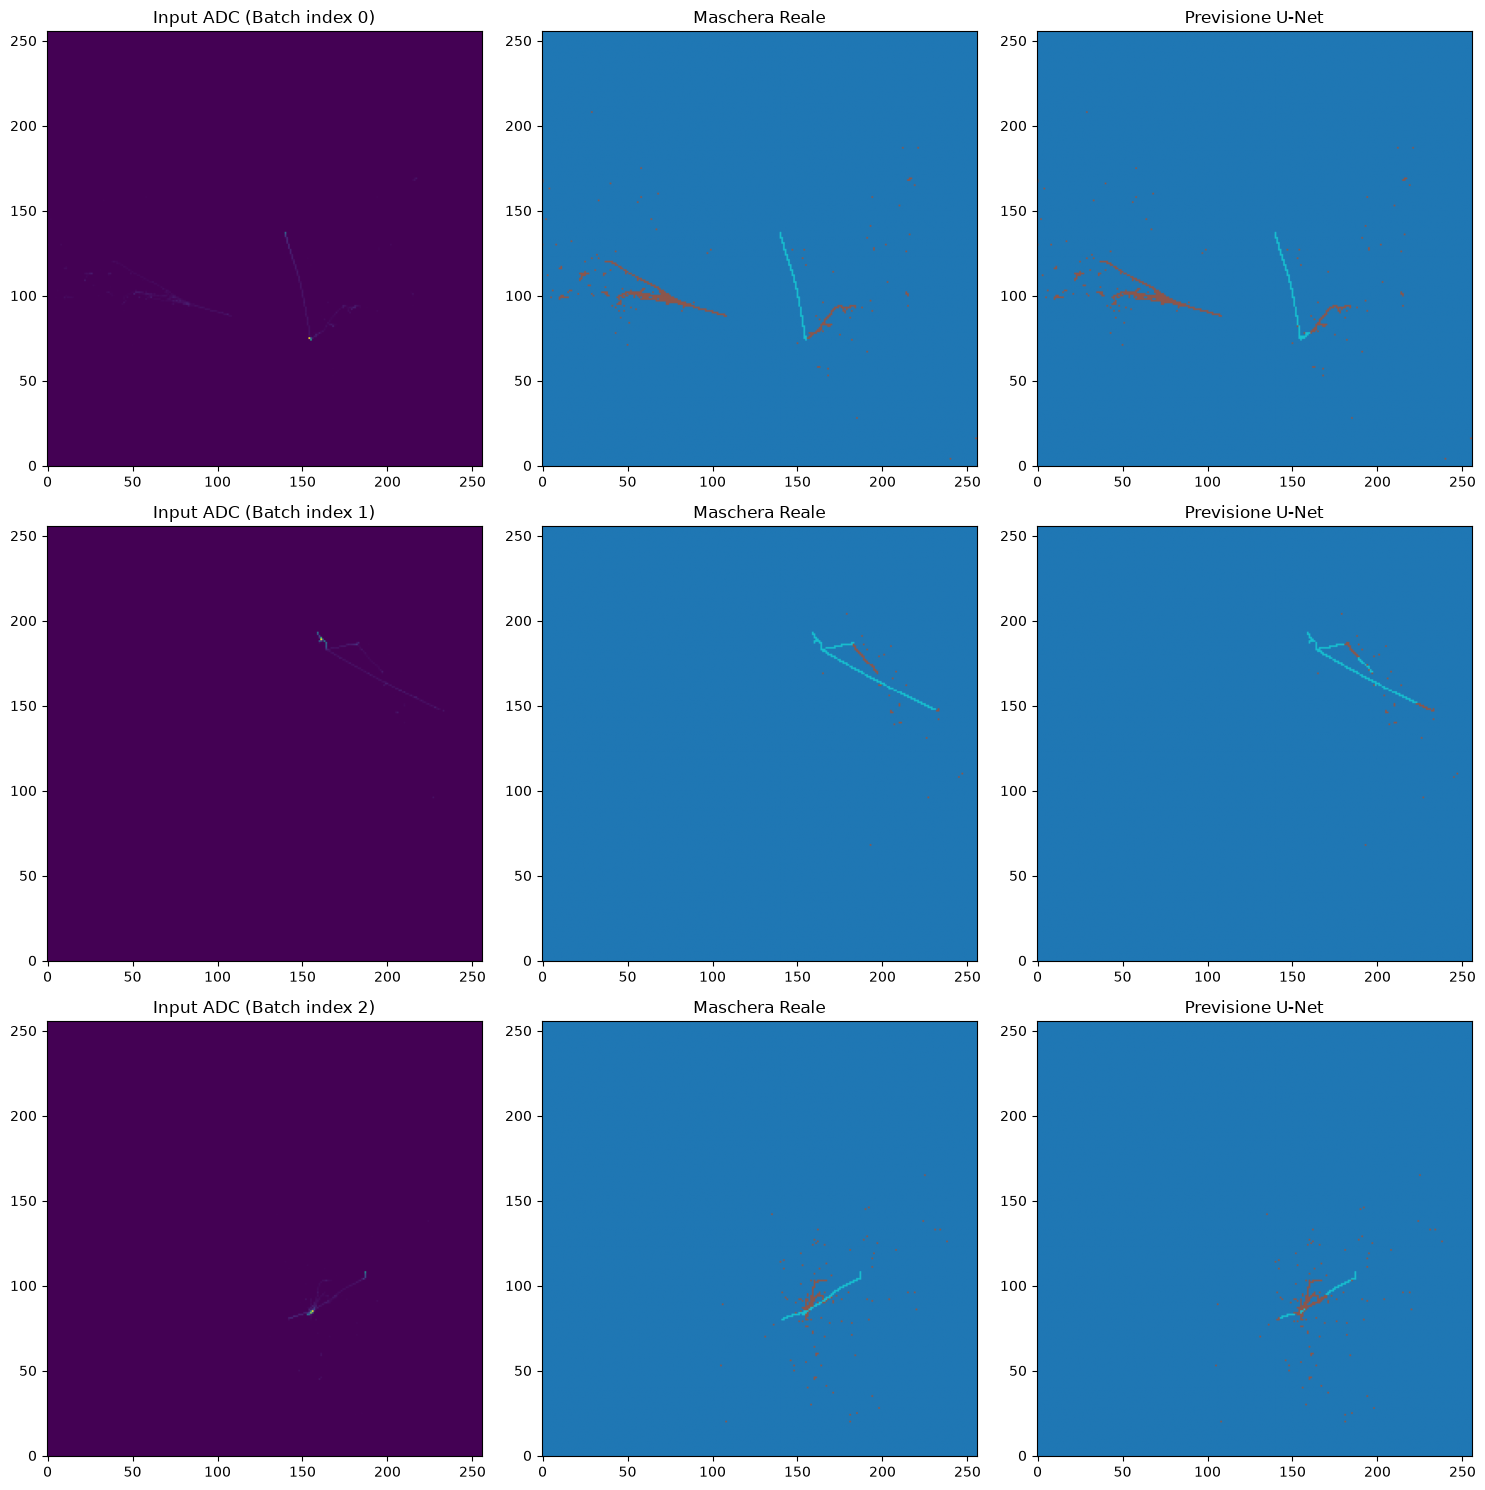

In [8]:
model.eval()

# Estrae un nuovo batch casuale di 16 eventi
test_images, test_masks = next(iter(dataloader))
test_images = test_images.to(device)
test_masks = test_masks.to(device)

with torch.no_grad():
    predictions = model(test_images)
    pred_labels = torch.argmax(predictions, dim=1)

# Numero di eventi da visualizzare (puoi mettere fino a 16)
n_view = 3 

fig, axes = plt.subplots(n_view, 3, figsize=(15, 5 * n_view))

for i in range(n_view):
    img_plot = test_images[i, 0].cpu().numpy()
    mask_plot = test_masks[i].cpu().numpy()
    pred_plot = pred_labels[i].cpu().numpy()

    # Colonna 1: Dati grezzi
    axes[i, 0].imshow(img_plot, cmap='viridis', origin='lower')
    axes[i, 0].set_title(f"Input ADC (Batch index {i})")
    
    # Colonna 2: Soluzione
    axes[i, 1].imshow(mask_plot, cmap='tab10', origin='lower', vmin=0, vmax=2)
    axes[i, 1].set_title("Maschera Reale")
    
    # Colonna 3: Rete Neurale
    axes[i, 2].imshow(pred_plot, cmap='tab10', origin='lower', vmin=0, vmax=2)
    axes[i, 2].set_title("Previsione U-Net")

plt.tight_layout()
plt.show()

Calcolo progressivo della Matrice di Confusione...


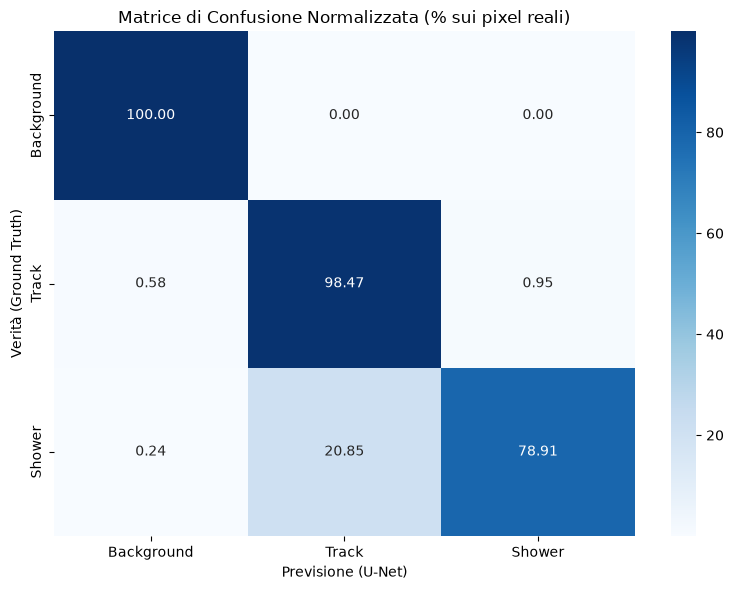

In [9]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

model.eval()

# Matrice dei conteggi assoluti 3x3
total_cm = np.zeros((3, 3), dtype=np.int64)

print("Calcolo progressivo della Matrice di Confusione...")

with torch.no_grad():
    for images, masks in dataloader:
        images = images.to(device)
        
        # Inferenza
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        
        # Flatten del singolo batch (solo 16 immagini alla volta in memoria)
        b_preds = preds.view(-1).cpu().numpy()
        b_masks = masks.view(-1).numpy()
        
        # Calcola la matrice del batch e sommala all'accumulatore globale
        total_cm += confusion_matrix(b_masks, b_preds, labels=[0, 1, 2])

# Normalizzazione per riga (Recall %) sui conteggi totali aggregati
cm_normalized = total_cm.astype('float') / total_cm.sum(axis=1)[:, np.newaxis] * 100

# Visualizzazione
plt.figure(figsize=(8, 6))
sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=["Background", "Track", "Shower"],
            yticklabels=["Background", "Track", "Shower"])

plt.ylabel('Verità (Ground Truth)')
plt.xlabel('Previsione (U-Net)')
plt.title('Matrice di Confusione Normalizzata (% sui pixel reali)')
plt.tight_layout()
plt.show()
plt.close()